<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Run this notebook](README.md)

# 01 · Align dates before comparing adjusted price paths

**How do we compare price paths without confusing dollar price, starting date, and missing observations?** We will fetch daily history for three fixed US listings, align their observed dates, rebase each vendor-adjusted close to 100, and calculate its decline from the highest value seen so far in the selected window.

This example reads **live Yahoo Finance data for a fixed historical window**, January–March 2024. Saved outputs identify the retrieval time; reruns may reflect vendor revisions. AAPL, MSFT and SPY are fixed examples of two equities and an ETF, not a selection rule or portfolio. No API key is required.

## Choose where the comparison starts

`DISPLAY_START` is an inclusive lower date bound within the fixed retrieval window. Change **2024-01-01 to 2024-02-01** for the experiment. The three upstream requests stay the same; the common-date cohort, base prices and in-window peaks are recomputed.

The endpoint is fixed and exclusive: **2024-04-01**. There is no interpolation or forward filling. The worker's timestamps are emitted in UTC; these US regular-session bars have the same calendar date in UTC and New York. This assumption is not a general exchange-calendar rule.

In [1]:
DISPLAY_START = "2024-01-01"

In [2]:
import os
import json
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
from datetime import date, datetime, timezone
from tempfile import TemporaryDirectory
import haybarn
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from notebook_support import theme, finish, prose

if not isinstance(DISPLAY_START, str):
    raise ValueError("DISPLAY_START must be an ISO date from 2024-01-01 through 2024-03-01.")
try:
    chosen = date.fromisoformat(DISPLAY_START)
except ValueError as exc:
    raise ValueError(
        "DISPLAY_START must be an ISO date from 2024-01-01 through 2024-03-01."
    ) from exc
if chosen.isoformat() != DISPLAY_START or not date(2024, 1, 1) <= chosen <= date(2024, 3, 1):
    raise ValueError("DISPLAY_START must be an ISO date from 2024-01-01 through 2024-03-01.")
retrieved_at = datetime.now(timezone.utc).isoformat(timespec="seconds")
source_line = "Yahoo Finance · Live retrieval " + retrieved_at + " · Historical daily bars"
secret_directory = TemporaryDirectory(prefix="vgi-yfinance-secrets-")
con = haybarn.connect(
    config={"secret_directory": secret_directory.name, "allow_persistent_secrets": False}
)
assert con.execute("SELECT count(*) FROM duckdb_secrets()").fetchall() == [(0,)]
paths = summary = coverage = checks = pd.DataFrame()
theme()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-yfinance/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-yfinance/notebooks/pyproject.toml.

## Attach a released worker and materialize the history once

`github-auto` downloads and verifies the platform-specific **v0.6.0** worker. The literal location works without a worker checkout or Bun installation. These are bounded public reads; network errors stop the run without substituting sample prices.

`LATERAL` supplies each ticker to `history`. `CREATE TABLE` stores the three responses so the remaining SQL and charts work from the same materialized values. The worker also offers search, current quotes and a static symbol registry; this analysis intentionally uses historical bars throughout.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
SET TimeZone='UTC';
ATTACH 'yfinance' AS yf (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-yfinance@v0.6.0');
CREATE TABLE tickers(symbol,asset_type) AS VALUES ('AAPL','Equity'),('MSFT','Equity'),('SPY','ETF');
CREATE TABLE history AS SELECT t.symbol,t.asset_type,h.timestamp,h.open,h.high,h.low,h.close,h.adjclose,h.volume
FROM tickers t,LATERAL yf.history(t.symbol,start_date:='2024-01-01',end_date:='2024-04-01',bar:='1d',prepost:=false) h;
SELECT symbol,count(*) AS bars,min(timestamp) AS first_bar_utc,max(timestamp) AS last_bar_utc,
 count(*) FILTER(WHERE adjclose IS NULL OR NOT isfinite(adjclose) OR adjclose<=0) AS unusable_adjusted_closes
FROM history GROUP BY symbol ORDER BY symbol;

,symbol,bars,first_bar_utc,last_bar_utc,unusable_adjusted_closes
0,AAPL,61,2024-01-02 09:30:00-05:00,2024-03-28 09:30:00-04:00,0
1,MSFT,61,2024-01-02 09:30:00-05:00,2024-03-28 09:30:00-04:00,0
2,SPY,61,2024-01-02 09:30:00-05:00,2024-03-28 09:30:00-04:00,0


In [4]:
prose(
    "**Live historical retrieval completed.** Run began at "
    + retrieved_at
    + ". The remaining cells query the materialized history; a future rerun may contain corrected or revised vendor values."
)

**Live historical retrieval completed.** Run began at 2026-11-14T10:55:05+00:00. The remaining cells query the materialized history; a future rerun may contain corrected or revised vendor values.

## Make the shared observation dates explicit

A missing candle is not a zero return. We retain dates with one finite, positive adjusted close for every requested symbol and report what the alignment excludes. Null or invalid values remain in `history` for inspection.

Yahoo's `close` and `adjclose` are different series. We use the vendor's adjusted series consistently; its adjustment factors can change when the vendor revises corporate-action data. An adjusted-price index is not a simulated investment account: this notebook does not model cash distributions, taxes, fees, execution, or reinvestment transactions.

In [5]:
%%sql
CREATE TABLE usable AS SELECT *,timestamp::DATE AS observation_date FROM history
WHERE adjclose IS NOT NULL AND isfinite(adjclose) AND adjclose>0;
CREATE TABLE common_dates AS SELECT observation_date FROM usable
WHERE observation_date>=DATE '{{ DISPLAY_START }}'
GROUP BY observation_date HAVING count(*)=(SELECT count(*) FROM tickers)
 AND count(DISTINCT symbol)=(SELECT count(*) FROM tickers);
CREATE TABLE aligned AS SELECT u.* FROM usable u JOIN common_dates USING(observation_date);
SELECT t.symbol,count(h.timestamp) AS source_bars_in_window,
 count(h.timestamp) FILTER(WHERE d.observation_date IS NOT NULL) AS retained_bars,
 count(h.timestamp) FILTER(WHERE d.observation_date IS NULL) AS excluded_source_bars
FROM tickers t LEFT JOIN history h ON h.symbol=t.symbol AND h.timestamp::DATE>=DATE '{{ DISPLAY_START }}'
LEFT JOIN common_dates d ON d.observation_date=h.timestamp::DATE GROUP BY t.symbol ORDER BY t.symbol;

,symbol,source_bars_in_window,retained_bars,excluded_source_bars
0,AAPL,61,61,0
1,MSFT,61,61,0
2,SPY,61,61,0


## Rebase each series and keep the peak calculation backward-looking

The base is each symbol's first **common observed date**, which may be later than `DISPLAY_START`. A value of 105 means the adjusted close is 5% above that base. Raw share prices are never added together.

The running peak uses `ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW`, so it cannot see future observations. Drawdown is `100 × (adjusted close / running peak − 1)`. It resets to zero at a new in-window high and is nonpositive. A high before our selected window is outside this definition; dropped dates can also omit extrema.

In [6]:
%%sql
CREATE TABLE measured AS SELECT *,
 first_value(adjclose) OVER(PARTITION BY symbol ORDER BY observation_date) AS base_adjusted_close,
 max(adjclose) OVER(PARTITION BY symbol ORDER BY observation_date ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS running_peak
FROM aligned;
CREATE TABLE comparison AS SELECT *,100*adjclose/base_adjusted_close AS adjusted_index,
 100*(adjclose/running_peak-1) AS drawdown_pct FROM measured;
SELECT symbol,min(observation_date) AS base_date,max(observation_date) AS last_date,
 count(*) AS observed_dates,round(min(base_adjusted_close),4) AS base_adjusted_close,
 round(arg_max(adjusted_index,observation_date),2) AS final_index,
 round(min(drawdown_pct),2) AS deepest_in_window_drawdown_pct
FROM comparison GROUP BY symbol ORDER BY symbol;

,symbol,base_date,last_date,observed_dates,base_adjusted_close,final_index,deepest_in_window_drawdown_pct
0,AAPL,2024-01-02,2024-03-28,61,183.2648,92.49,-13.30
1,MSFT,2024-01-02,2024-03-28,61,363.1179,113.65,-4.21
2,SPY,2024-01-02,2024-03-28,61,457.6727,111.01,-1.71


In [7]:
%%sql paths <<
SELECT symbol,observation_date,adjclose,adjusted_index,running_peak,drawdown_pct
FROM comparison ORDER BY symbol,observation_date;

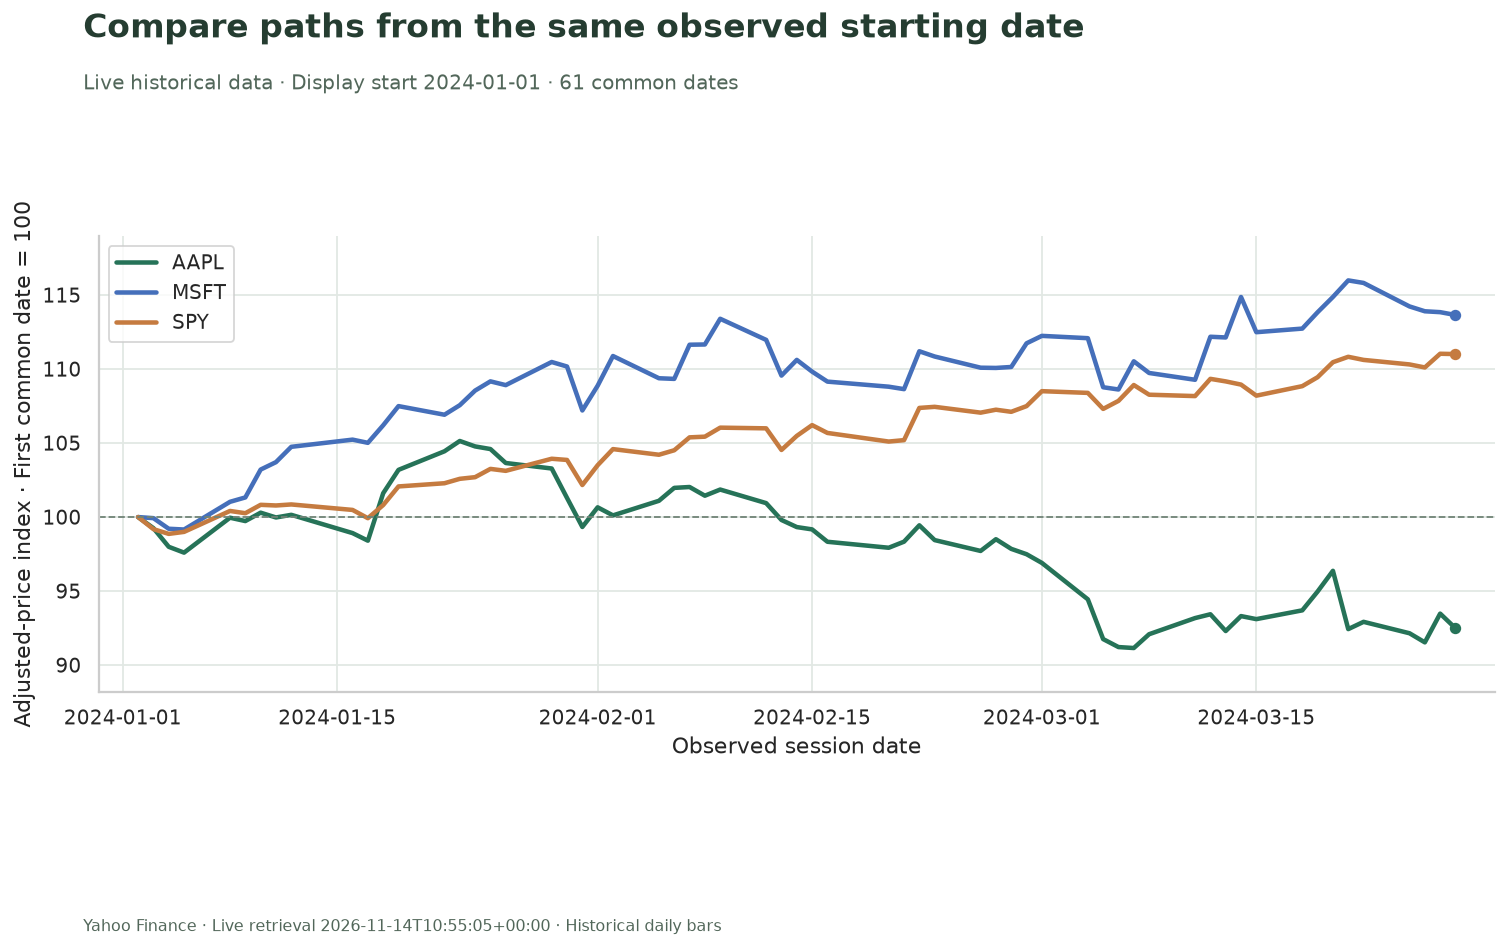

**Each line starts at 100 on the same observed date.** The index removes the dollar-price scale, but does not make these instruments economically interchangeable or predict their future paths.

In [8]:
assert len(paths) > 0 and paths.groupby("symbol").size().min() >= 2, (
    "Need at least two common dates per symbol."
)
fig, ax = plt.subplots(figsize=(12, 7.4))
colors = {"AAPL": "#267358", "MSFT": "#456fba", "SPY": "#c57b40"}
for symbol, rows in paths.groupby("symbol", sort=True):
    ax.plot(
        pd.to_datetime(rows.observation_date),
        rows.adjusted_index,
        label=symbol,
        color=colors[symbol],
        linewidth=2.5,
    )
    ax.scatter(
        pd.to_datetime(rows.observation_date.iloc[-1]),
        rows.adjusted_index.iloc[-1],
        color=colors[symbol],
        s=28,
    )
ax.axhline(100, color="#708377", linewidth=1, linestyle="--")
ax.set_ylabel("Adjusted-price index · First common date = 100")
ax.set_xlabel("Observed session date")
ax.legend(loc="best", frameon=True)
ax.margins(x=0.03, y=0.12)
finish(
    fig,
    "Compare paths from the same observed starting date",
    f"Live historical data · Display start {DISPLAY_START} · {paths.observation_date.nunique()} common dates",
    "01_adjusted_price_paths.png",
    source=source_line,
    bottom=0.18,
)
prose(
    "**Each line starts at 100 on the same observed date.** The index removes the dollar-price scale, but does not make these instruments economically interchangeable or predict their future paths."
)

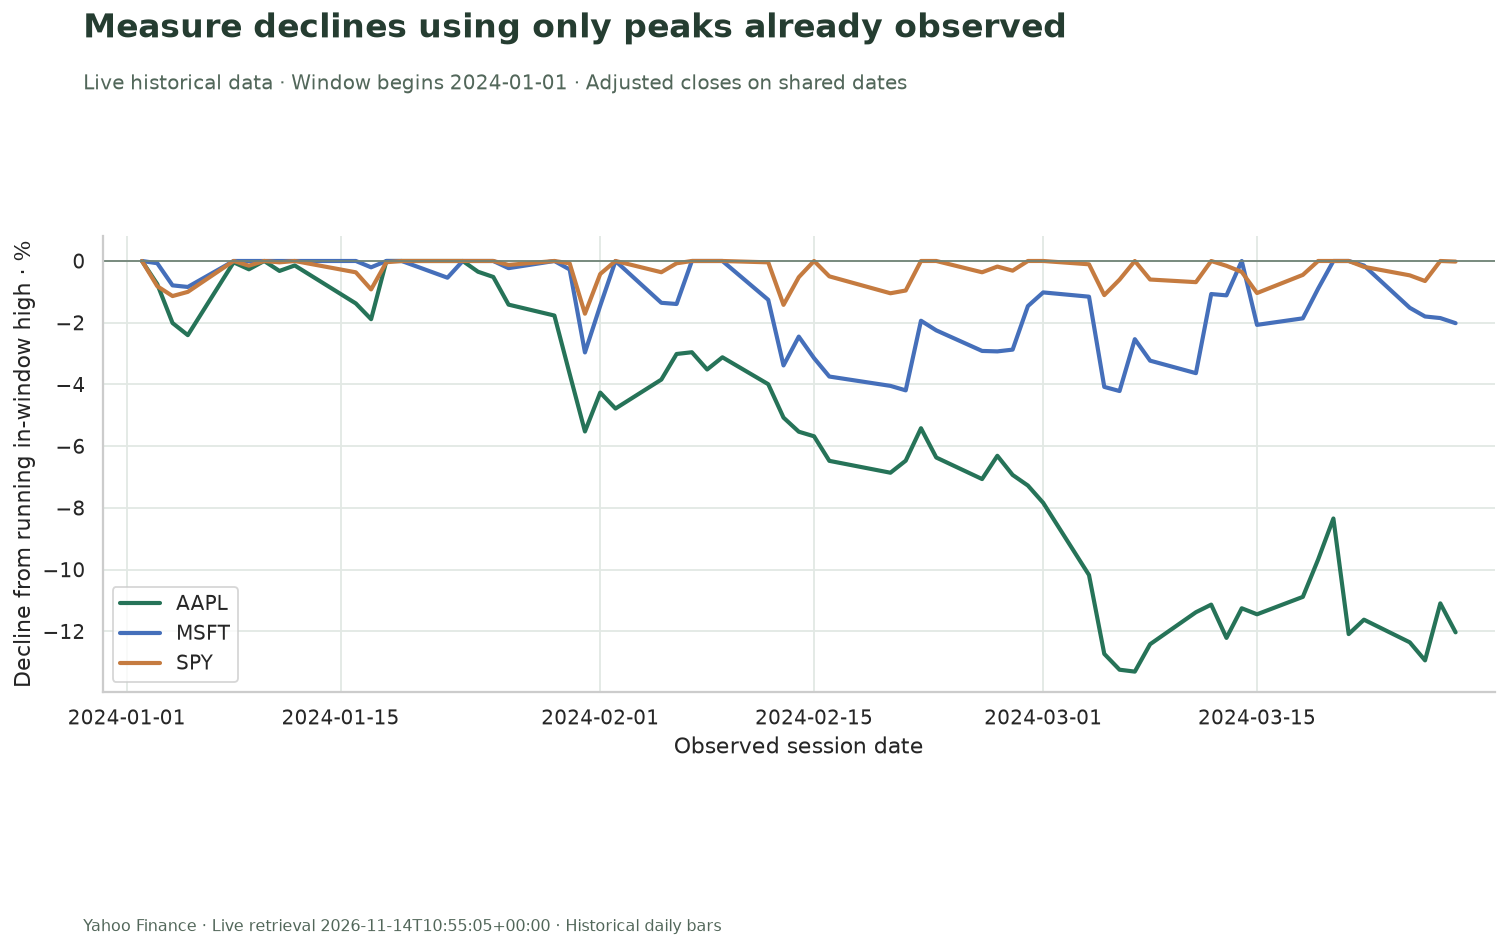

**This is an in-window drawdown.** Moving the start date can remove an earlier peak and change the curve even when every retained price is unchanged. Zero means a new or matched selected-window high, not zero risk.

In [9]:
fig, ax = plt.subplots(figsize=(12, 7.4))
for symbol, rows in paths.groupby("symbol", sort=True):
    ax.plot(
        pd.to_datetime(rows.observation_date),
        rows.drawdown_pct,
        label=symbol,
        color=colors[symbol],
        linewidth=2.3,
    )
ax.axhline(0, color="#708377", linewidth=1)
ax.set_ylabel("Decline from running in-window high · %")
ax.set_xlabel("Observed session date")
ax.set_ylim(top=0.8)
ax.legend(loc="best", frameon=True)
ax.margins(x=0.03)
finish(
    fig,
    "Measure declines using only peaks already observed",
    f"Live historical data · Window begins {DISPLAY_START} · Adjusted closes on shared dates",
    "02_in_window_drawdowns.png",
    source=source_line,
    bottom=0.18,
)
prose(
    "**This is an in-window drawdown.** Moving the start date can remove an earlier peak and change the curve even when every retained price is unchanged. Zero means a new or matched selected-window high, not zero risk."
)

## Inspect the adjustment and check the relationships

The first and last vendor adjustment factors show why the adjusted series should be identified explicitly. These ratios are descriptive, not a reconstruction of individual corporate actions. Mechanical checks below validate alignment, rebasings and past-only peaks; they do not establish data completeness or investment suitability.

In [10]:
%%sql
SELECT symbol,arg_min(close,observation_date) AS first_close,
 arg_min(adjclose,observation_date) AS first_adjusted_close,
 arg_max(close,observation_date) AS last_close,arg_max(adjclose,observation_date) AS last_adjusted_close,
 arg_min(adjclose/nullif(close,0),observation_date) AS first_adjustment_factor,
 arg_max(adjclose/nullif(close,0),observation_date) AS last_adjustment_factor
FROM aligned GROUP BY symbol ORDER BY symbol;

,symbol,first_close,first_adjusted_close,last_close,last_adjusted_close,first_adjustment_factor,last_adjustment_factor
0,AAPL,185.639999,183.264771,171.479996,169.501953,0.987205,0.988465
1,MSFT,370.869995,363.117859,420.720001,412.687714,0.979097,0.980908
2,SPY,472.649994,457.672729,523.070007,508.068787,0.968312,0.971321


In [11]:
%%sql checks <<
SELECT 'All requested symbols returned history' AS check_name,(SELECT count(DISTINCT symbol) FROM history)=(SELECT count(*) FROM tickers) AS passed
UNION ALL SELECT 'Source symbol and timestamp keys are unique',count(*)=count(DISTINCT (symbol,timestamp)) FROM history
UNION ALL SELECT 'Source dates respect the exclusive end',bool_and(timestamp::DATE>=DATE '2024-01-01' AND timestamp::DATE<DATE '2024-04-01') FROM history
UNION ALL SELECT 'At least two common dates remain',(SELECT count(*) FROM common_dates)>=2
UNION ALL SELECT 'Each common date has every requested symbol',bool_and(n=3) FROM(SELECT observation_date,count(DISTINCT symbol) AS n FROM aligned GROUP BY observation_date)
UNION ALL SELECT 'Alignment respects the selected start',bool_and(observation_date>=DATE '{{ DISPLAY_START }}') FROM aligned
UNION ALL SELECT 'Selected adjusted closes are finite and positive',bool_and(isfinite(adjclose) AND adjclose>0) FROM aligned
UNION ALL SELECT 'Each rebased path starts at 100',bool_and(abs(start_index-100)<1e-9) FROM(SELECT symbol,arg_min(adjusted_index,observation_date) AS start_index FROM comparison GROUP BY symbol)
UNION ALL SELECT 'Running peaks never decrease',bool_and(previous_peak IS NULL OR running_peak>=previous_peak) FROM(SELECT *,lag(running_peak) OVER(PARTITION BY symbol ORDER BY observation_date) AS previous_peak FROM comparison)
UNION ALL SELECT 'Running peaks equal a direct past-only maximum',bool_and(abs(c.running_peak-(SELECT max(p.adjclose) FROM aligned p WHERE p.symbol=c.symbol AND p.observation_date<=c.observation_date))<1e-9) FROM comparison c
UNION ALL SELECT 'Drawdowns lie between minus100 and zero',bool_and(drawdown_pct > -100 AND drawdown_pct<=1e-9) FROM comparison
UNION ALL SELECT 'Every plotted symbol has the same observation count',min(n)=max(n) FROM(SELECT symbol,count(*) AS n FROM comparison GROUP BY symbol);

In [12]:
display(checks)
assert len(checks) == 12 and checks.passed.fillna(False).all(), checks
prose(
    f"**All {len(checks)} relationship checks passed.** {len(paths)} plotted observations across {paths.observation_date.nunique()} shared dates. Live retrieval began {retrieved_at}."
)

export = Path("validation/data")
export.mkdir(parents=True, exist_ok=True)
con.execute("SELECT * FROM history ORDER BY symbol,timestamp").fetchdf().to_csv(
    export / "history.csv", index=False
)
paths.to_csv(export / "comparison.csv", index=False)
_ = (export / "run.json").write_text(
    json.dumps(
        {
            "retrieval_started_utc": retrieved_at,
            "DISPLAY_START": DISPLAY_START,
            "source_start": "2024-01-01",
            "source_end_exclusive": "2024-04-01",
            "worker_release": "v0.6.0",
        },
        indent=2,
    )
    + "\n"
)

,check_name,passed
0,All requested symbols returned history,True
1,Source symbol and timestamp keys are unique,True
2,Source dates respect the exclusive end,True
3,At least two common dates remain,True
4,Each common date has every requested symbol,True
5,Alignment respects the selected start,True
6,Selected adjusted closes are finite and positive,True
7,Each rebased path starts at 100,True
8,Running peaks never decrease,True
9,Running peaks equal a direct past-only maximum,True


**All 12 relationship checks passed.** 183 plotted observations across 61 shared dates. Live retrieval began 2026-11-14T10:55:05+00:00.

## Try one controlled change

Set **`DISPLAY_START = "2024-02-01"`**, restart the kernel and run all. The requested historical period stays January–March; the selected base date and running-peak window move. Predict which chart values change even though the overlapping adjusted closes do not.

The runner requires a separate output directory for this experiment, preserving the successful default notebook. Because each run makes new live requests, compare raw values before calling this a controlled data comparison: vendor revisions or failures are possible. Reset to **`"2024-01-01"`** afterward.

For another worker-assisted extension, use VGI Trading Calendar to compare observed dates against a separately specified exchange calendar. Do not infer that absent dates are exchange holidays from price history alone.

During validation, 119 of 183 adjusted closes differed slightly between consecutive live runs (maximum absolute difference 0.000123; maximum relative difference below 0.000025%). Other source columns matched exactly. The experiment agreed with a recomputation on the first run's fixed prices within 0.0001 index or percentage points. These are observed run differences, not a promised precision bound.

In [13]:
con.close()
secret_directory.cleanup()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Yahoo Finance](https://finance.yahoo.com/) · [Yahoo terms](https://legal.yahoo.com/us/en/yahoo/terms/otos/index.html)